In [8]:
%load_ext autoreload
%autoreload 2

import numpy as np
import time
from py_files.experiment_stats import (var_vs_params)
from py_files.functions import (calculate_barlet_values, calculate_capon_values, get_sin_signal, get_impulse_signal, calculate_stiring_matrix, calculate_complex_stiring_matrix)
from py_files.configs.config import init_rng, restart_rng
import py_files.configs.config as cfg
import py_files.configs.comon as comon
from py_files.plot_scrip import plot_variance_vs_param
import os
origin_config = init_rng()
sin_signal = get_sin_signal
path = "attachment/images/report"
os.makedirs(path,exist_ok=True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [9]:
config_parametrs1 = restart_rng(origin_config)
config_parametrs2 = restart_rng(origin_config)
start_time = time.perf_counter()

var_barlett_vs_phis = var_vs_params(config_params=config_parametrs1,
                                   energy_func=calculate_barlet_values,
                                   signal_func = sin_signal,
                                   parametr_name = "target_phi",
                                   parametr_values = cfg.PHI_VALUES,
                                   stiring_func= calculate_stiring_matrix
                                   )

var_barlett_vs_phis_complex = var_vs_params(config_params = config_parametrs2,
                                   energy_func = calculate_barlet_values,
                                   signal_func = sin_signal,
                                   parametr_name = "target_phi",
                                   parametr_values = cfg.PHI_VALUES,
                                   stiring_func= calculate_complex_stiring_matrix
                                   )

end_time = time.perf_counter()
delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='$\\varphi_0, град$', ylabel='$s_{\\varepsilon}^{2}$, $град^2$'>)

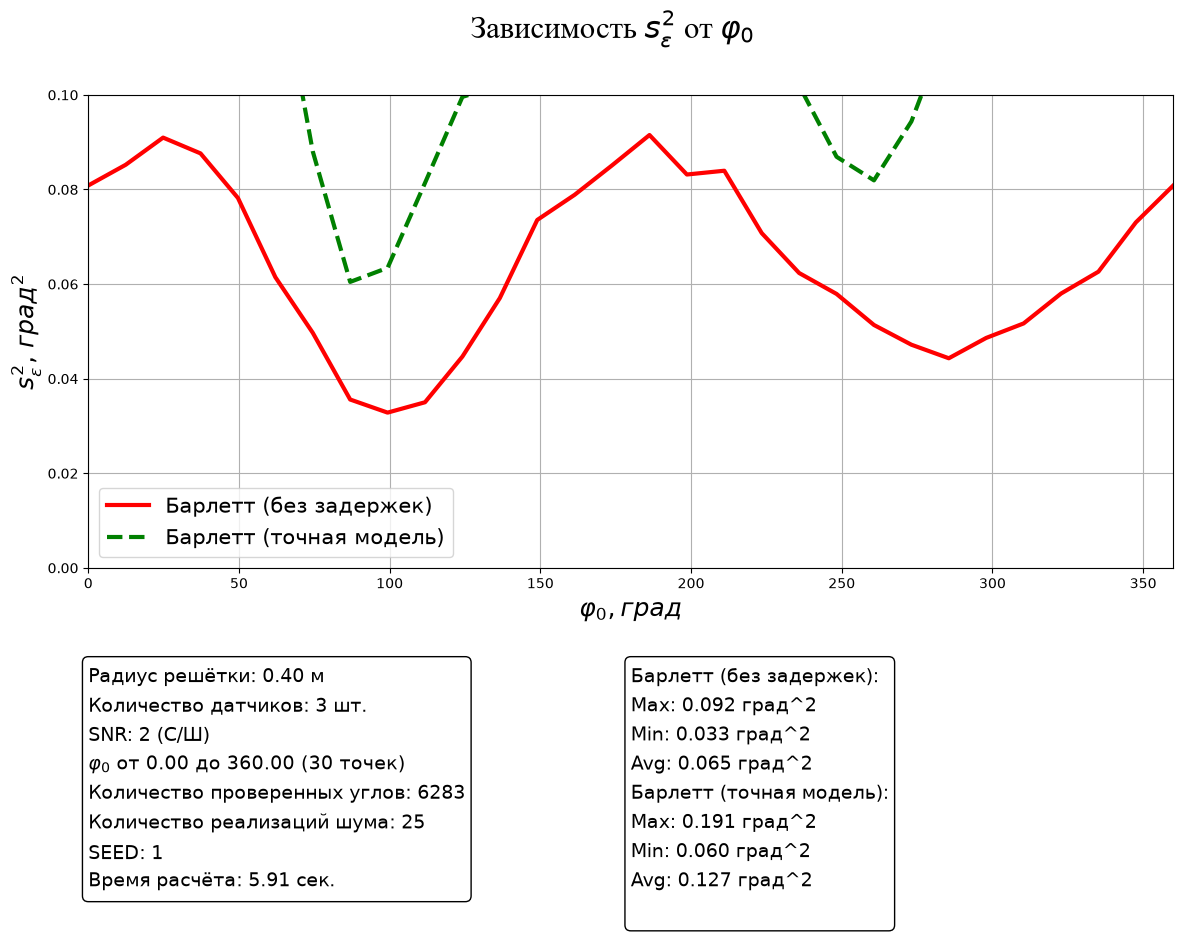

In [10]:
plot_variance_vs_param(dict_values = {"Барлетт (без задержек)": var_barlett_vs_phis,
                                      "Барлетт (точная модель)": var_barlett_vs_phis_complex},
                       config_params = origin_config.copy(),
                       parametr_values = cfg.PHI_VALUES,
                       parametr_name = "phis",
                       delta_time = delta_time,
                       ylim = (0.00*comon.CONST_RADIAN, 0.1*comon.CONST_RADIAN),
                       xlim = (0,360)
                       )

In [19]:
config_parametrs1 = restart_rng(origin_config)
config_parametrs2 = restart_rng(origin_config)
SNR_VALUES = np.linspace(1, 10, 10)
start_time = time.perf_counter()
    
        
end_time = time.perf_counter()
delta_time = end_time - start_time
var_barlett_vs_snr = var_vs_params(config_params=config_parametrs1,
                                   energy_func=calculate_barlet_values,
                                   signal_func = sin_signal,
                                   parametr_name = "snr",
                                   parametr_values = SNR_VALUES,
                                   stiring_func = calculate_stiring_matrix
                                   )

var_barlett_vs_snr_complex = var_vs_params(config_params = config_parametrs2,
                                   energy_func = calculate_barlet_values,
                                   signal_func = sin_signal,
                                   parametr_name = "snr",
                                   parametr_values = SNR_VALUES,
                                   stiring_func = calculate_complex_stiring_matrix)

end_time = time.perf_counter()
delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='SNR (c/ш)', ylabel='$s_{\\varepsilon}^{2}$, $град^2$'>)

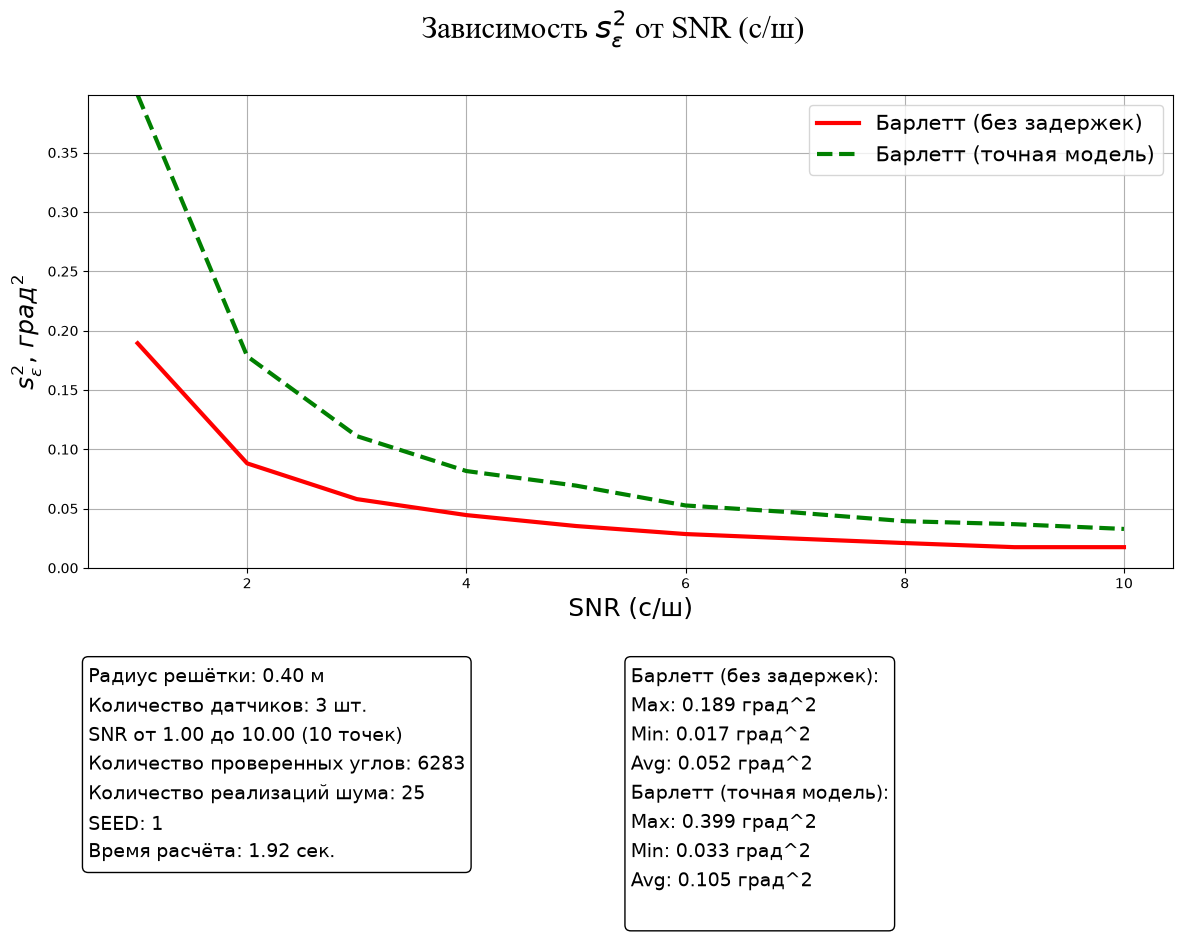

In [20]:
plot_variance_vs_param(dict_values = {"Барлетт (без задержек)": var_barlett_vs_snr,
                                      "Барлетт (точная модель)": var_barlett_vs_snr_complex},
                       config_params = origin_config.copy(),
                       parametr_values = SNR_VALUES,
                       parametr_name = "snr",
                       delta_time = delta_time,
                       ylim = (0, max(max(var_barlett_vs_snr),max(var_barlett_vs_snr_complex)))
                       )

In [ ]:
config_parametrs1 = restart_rng(origin_config)
config_parametrs2 = restart_rng(origin_config)
start_time = time.perf_counter()

var_barlett_vs_r = var_vs_params(config_params = config_parametrs1.copy(),
                              energy_func = calculate_barlet_values,
                              signal_func = sin_signal,
                              parametr_name = "R",
                              parametr_values = cfg.RADIUS_VALUES)


var_cap_vs_r = var_vs_params(config_params = config_parametrs2.copy(),
                              energy_func = calculate_capon_values,
                              signal_func = sin_signal,
                              parametr_name = "R",
                              parametr_values = cfg.RADIUS_VALUES)

end_time = time.perf_counter()
delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='R (радиус решётки АВП), м', ylabel='$s_{\\varepsilon}^{2}$, $град^2$'>)

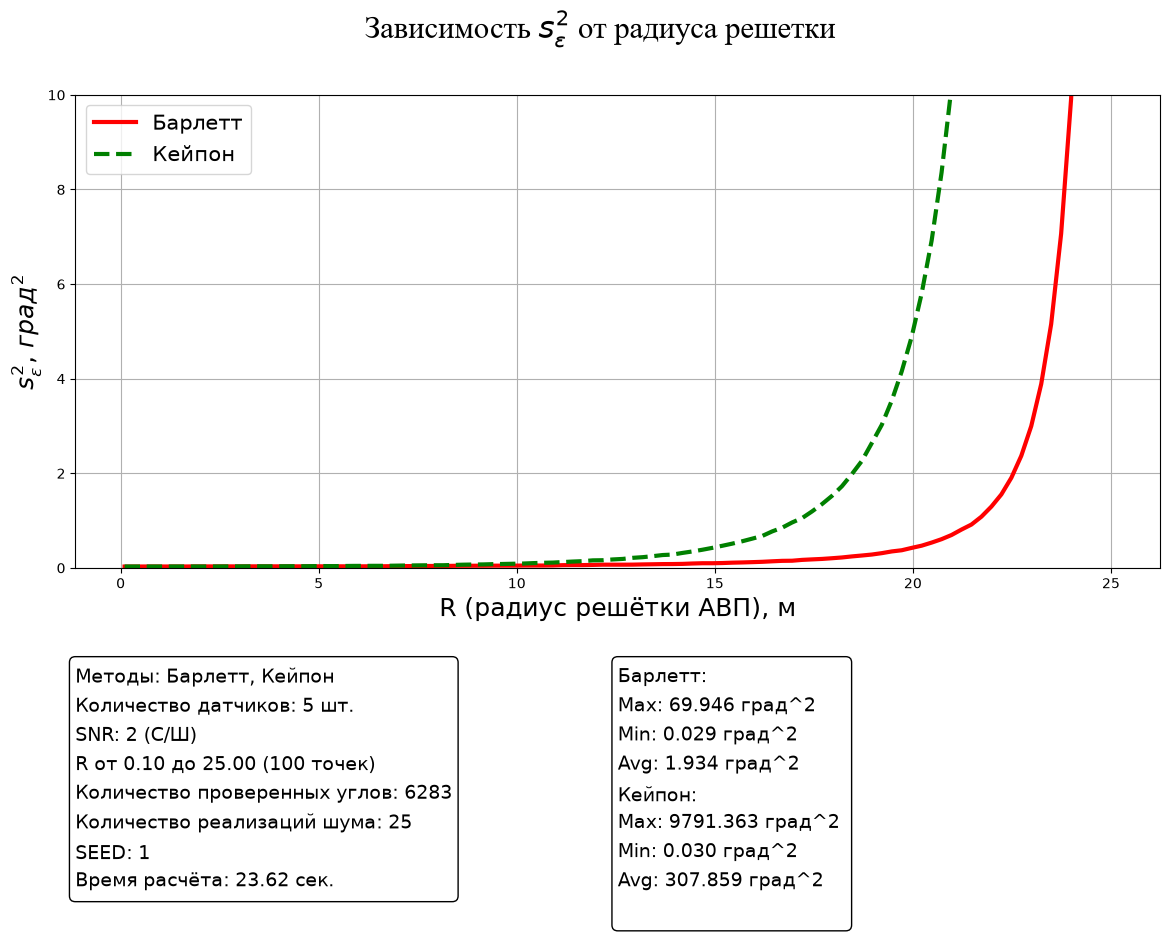

In [ ]:
plot_variance_vs_param(dict_values = {"Барлетт": var_barlett_vs_r,
                                      "Кейпон": var_cap_vs_r},
                       config_params = origin_config.copy(),
                       parametr_values = cfg.RADIUS_VALUES,
                       parametr_name = "R",
                       delta_time = delta_time,
                       ylim = (0, 10*comon.CONST_RADIAN)
                       )

In [ ]:
config_parametrs1 = restart_rng(origin_config)
config_parametrs2 = restart_rng(origin_config)
start_time = time.perf_counter()

var_barlett_vs_m = var_vs_params(config_params = config_parametrs1,
                              energy_func = calculate_barlet_values,
                              signal_func = sin_signal,
                              parametr_name = "M",
                              parametr_values = cfg.SENSOR_VALUES)


var_cap_vs_m = var_vs_params(config_params = config_parametrs2,
                              energy_func = calculate_capon_values,
                              signal_func = sin_signal,
                              parametr_name = "M",
                              parametr_values = cfg.SENSOR_VALUES)

end_time = time.perf_counter()
delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='M (кол-во датчиков), шт', ylabel='$s_{\\varepsilon}^{2}$, $град^2$'>)

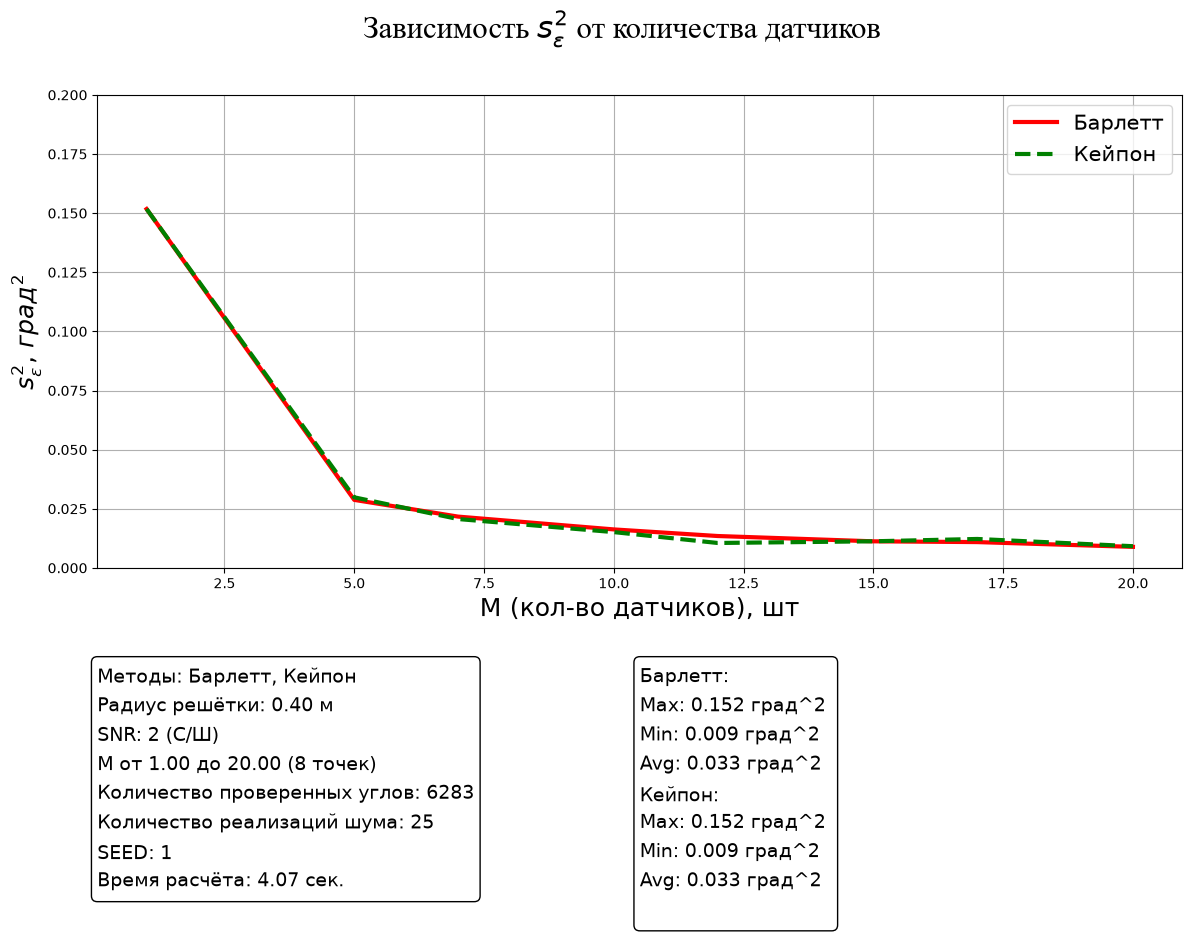

In [ ]:
plot_variance_vs_param(dict_values = {"Барлетт": var_barlett_vs_m,
                                      "Кейпон": var_cap_vs_m},
                       config_params = origin_config.copy(),
                       parametr_values = cfg.SENSOR_VALUES,
                       parametr_name = "M",
                       delta_time = delta_time,
                       ylim = (0, 0.2*comon.CONST_RADIAN)
                       )